In [2]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

print("TensorFlow version:", tf.__version__)
print("NumPy version:", np.__version__)
print("All libraries imported successfully!")

TensorFlow version: 2.21.0
NumPy version: 2.5.4
All libraries imported successfully!


In [2]:
%pip install tensorflow

   ---------------------------------------- 0.0/350.9 MB ? eta -:--:--
   ---------------------------------------- 1.0/350.9 MB 5.0 MB/s eta 0:01:10
   ---------------------------------------- 1.8/350.9 MB 4.6 MB/s eta 0:01:17
   ---------------------------------------- 2.6/350.9 MB 4.1 MB/s eta 0:01:26
   ---------------------------------------- 3.7/350.9 MB 4.3 MB/s eta 0:01:22
   ---------------------------------------- 4.2/350.9 MB 4.1 MB/s eta 0:01:26
    --------------------------------------- 5.2/350.9 MB 4.1 MB/s eta 0:01:25
    --------------------------------------- 6.0/350.9 MB 4.1 MB/s eta 0:01:26
    --------------------------------------- 6.8/350.9 MB 4.1 MB/s eta 0:01:25
    --------------------------------------- 7.9/350.9 MB 4.1 MB/s eta 0:01:25
    --------------------------------------- 8.7/350.9 MB 4.0 MB/s eta 0:01:25
   - -------------------------------------- 9.4/350.9 MB 4.1 MB/s eta 0:01:25
   - -------------------------------------- 10.2/350.9 MB 4.0 MB/s eta 

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: C:\Users\LaptopUser\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [3]:
from tensorflow.keras.datasets import mnist

(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


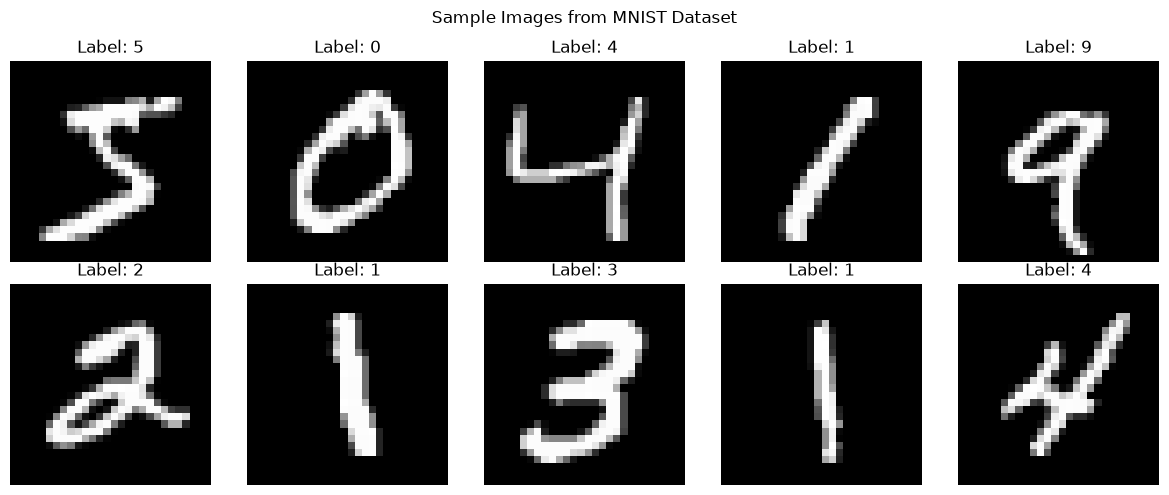

In [4]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.suptitle("Sample Images from MNIST Dataset")
plt.tight_layout()
plt.savefig("visualization_1_mnist_samples.png", dpi=300)
plt.show()

In [5]:
# Normalise pixel values
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Reshape images for CNN input
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Training data shape: (60000, 28, 28, 1)
Testing data shape: (10000, 28, 28, 1)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, Flatten,
    Dense, Dropout
)

model = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),

    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)                    │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Model compiled successfully!")

Model compiled successfully!


In [9]:
history = model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 17s 34ms/step - accuracy: 0.9211 - loss: 0.2623 - val_accuracy: 0.9835 - val_loss: 0.0659
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 33ms/step - accuracy: 0.9776 - loss: 0.0726 - val_accuracy: 0.9880 - val_loss: 0.0469
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 32ms/step - accuracy: 0.9827 - loss: 0.0546 - val_accuracy: 0.9887 - val_loss: 0.0384
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 13s 32ms/step - accuracy: 0.9866 - loss: 0.0433 - val_accuracy: 0.9913 - val_loss: 0.0312
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 14s 32ms/step - accuracy: 0.9890 - loss: 0.0353 - val_accuracy: 0.9920 - val_loss: 0.0310


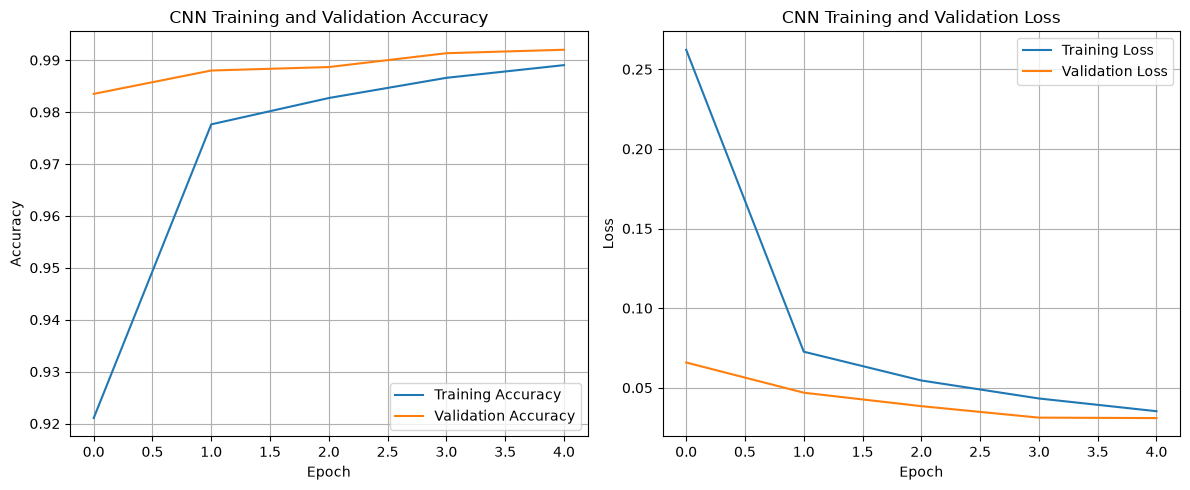

In [10]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('CNN Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('CNN Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig('visualization_2_training_performance.png', dpi=300)
plt.show()

In [11]:
from sklearn.metrics import accuracy_score, classification_report

y_prob = model.predict(X_test)
y_pred = np.argmax(y_prob, axis=1)

test_accuracy = accuracy_score(y_test, y_pred)

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
Test Accuracy: 99.12 %

Classification Report:

              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       1.00      0.99      0.99      1010
           4       1.00      0.99      0.99       982
           5       0.98      0.99      0.98       892
           6       1.00      0.99      0.99       958
           7       0.99      0.99      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.98      0.99      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



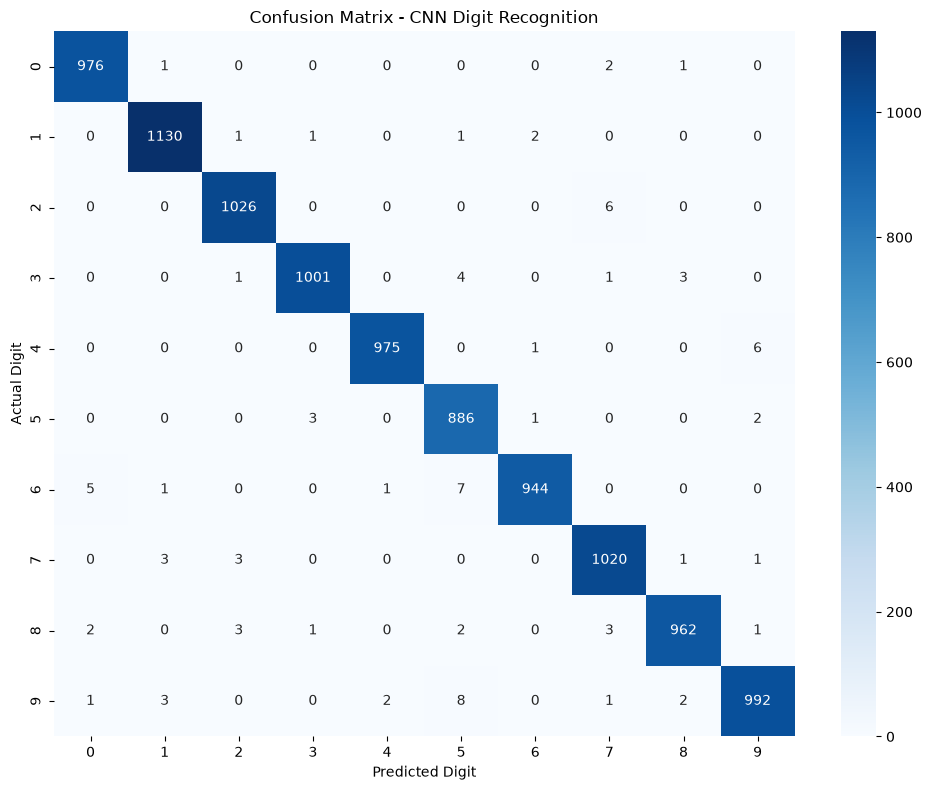

In [12]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.title('Confusion Matrix - CNN Digit Recognition')
plt.xlabel('Predicted Digit')
plt.ylabel('Actual Digit')
plt.tight_layout()
plt.savefig('visualization_3_confusion_matrix.png', dpi=300)
plt.show()

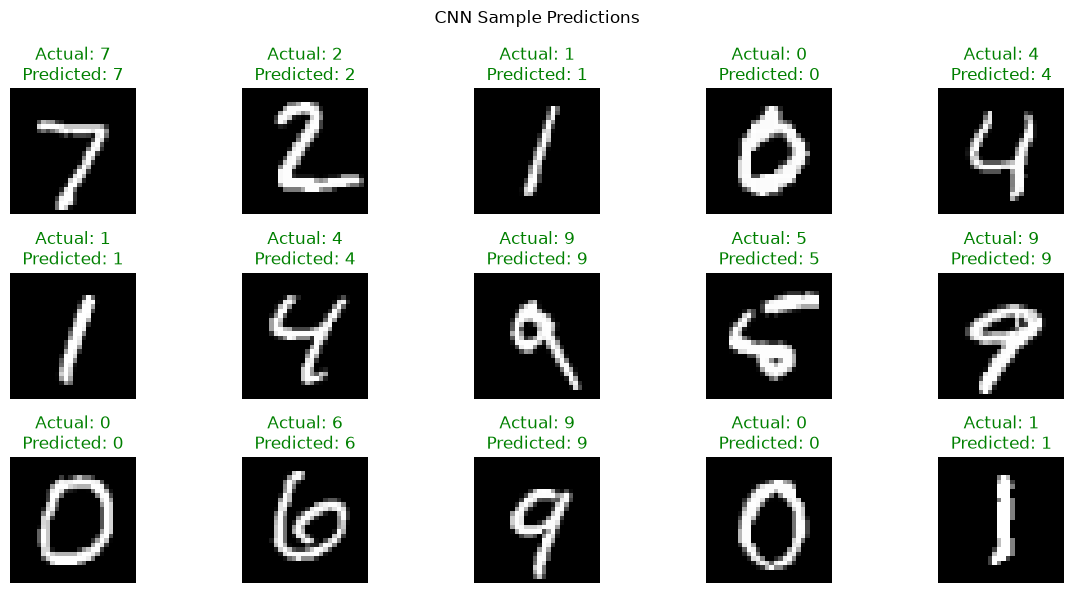

In [13]:
plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    predicted = y_pred[i]
    actual = y_test[i]

    color = 'green' if predicted == actual else 'red'

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color
    )
    plt.axis('off')

plt.suptitle("CNN Sample Predictions")
plt.tight_layout()
plt.savefig('visualization_4_sample_predictions.png', dpi=300)
plt.show()

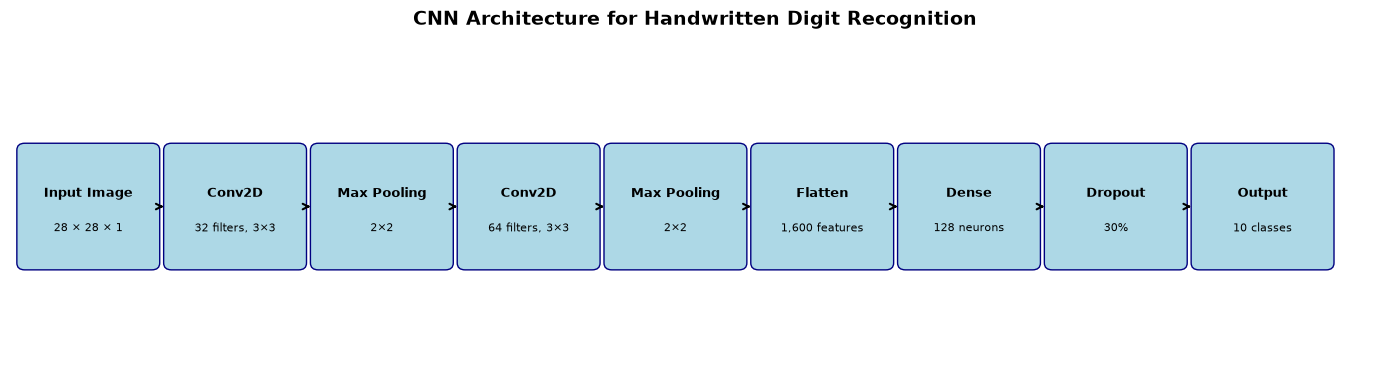

In [14]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(14, 4))
ax.set_xlim(0, 14)
ax.set_ylim(0, 4)
ax.axis('off')

layers = [
    ("Input Image", "28 × 28 × 1"),
    ("Conv2D", "32 filters, 3×3"),
    ("Max Pooling", "2×2"),
    ("Conv2D", "64 filters, 3×3"),
    ("Max Pooling", "2×2"),
    ("Flatten", "1,600 features"),
    ("Dense", "128 neurons"),
    ("Dropout", "30%"),
    ("Output", "10 classes")
]

positions = np.linspace(0.8, 12.8, len(layers))

for i, (name, detail) in enumerate(layers):
    x = positions[i]

    box = FancyBboxPatch(
        (x - 0.65, 1.35), 1.3, 1.3,
        boxstyle="round,pad=0.08",
        facecolor='lightblue',
        edgecolor='navy'
    )
    ax.add_patch(box)

    ax.text(x, 2.15, name, ha='center',
            va='center', fontsize=9, weight='bold')
    ax.text(x, 1.75, detail, ha='center',
            va='center', fontsize=8)

    if i < len(layers) - 1:
        ax.annotate(
            "",
            xy=(positions[i+1] - 0.7, 2),
            xytext=(x + 0.7, 2),
            arrowprops=dict(arrowstyle="->", lw=1.5)
        )

plt.title("CNN Architecture for Handwritten Digit Recognition",
          fontsize=14, weight='bold')
plt.tight_layout()
plt.savefig('visualization_5_cnn_architecture.png', dpi=300,
            bbox_inches='tight')
plt.show()

In [15]:
print("Model Summary")
print("Total Parameters:", model.count_params())
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Final Training Accuracy:",
      round(history.history['accuracy'][-1] * 100, 2), "%")
print("Final Validation Accuracy:",
      round(history.history['val_accuracy'][-1] * 100, 2), "%")
print("Final Training Loss:",
      round(history.history['loss'][-1], 4))
print("Final Validation Loss:",
      round(history.history['val_loss'][-1], 4))

Model Summary
Total Parameters: 225034
Test Accuracy: 99.12 %
Final Training Accuracy: 98.9 %
Final Validation Accuracy: 99.2 %
Final Training Loss: 0.0353
Final Validation Loss: 0.031


In [16]:
model.save("handwritten_digit_cnn.keras")

print("Trained CNN model saved successfully!")

Trained CNN model saved successfully!


In [17]:
%pip install python-docx

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: C:\Users\LaptopUser\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [18]:
import os

files = [
    "visualization_1_mnist_samples.png",
    "visualization_2_training_performance.png",
    "visualization_3_confusion_matrix.png",
    "visualization_4_sample_predictions.png",
    "visualization_5_cnn_architecture.png",
    "handwritten_digit_cnn.keras"
]

for file in files:
    print(file, "✓" if os.path.exists(file) else "MISSING")

visualization_1_mnist_samples.png ✓
visualization_2_training_performance.png ✓
visualization_3_confusion_matrix.png ✓
visualization_4_sample_predictions.png ✓
visualization_5_cnn_architecture.png ✓
handwritten_digit_cnn.keras ✓


In [19]:
from docx import Document
from docx.shared import Inches, Pt, RGBColor
from docx.enum.text import WD_ALIGN_PARAGRAPH
from docx.enum.section import WD_SECTION
from docx.enum.table import WD_TABLE_ALIGNMENT, WD_CELL_VERTICAL_ALIGNMENT
from docx.oxml import OxmlElement
from docx.oxml.ns import qn
from docx.enum.style import WD_STYLE_TYPE

doc = Document()

# Page layout
section = doc.sections[0]
section.top_margin = Inches(0.7)
section.bottom_margin = Inches(0.7)
section.left_margin = Inches(0.8)
section.right_margin = Inches(0.8)

# Default font
styles = doc.styles
styles['Normal'].font.name = 'Calibri'
styles['Normal'].font.size = Pt(10.5)

for style_name in ['Heading 1', 'Heading 2']:
    styles[style_name].font.name = 'Calibri'
    styles[style_name].font.color.rgb = RGBColor(31, 78, 121)

styles['Heading 1'].font.size = Pt(16)
styles['Heading 1'].font.bold = True
styles['Heading 2'].font.size = Pt(12)
styles['Heading 2'].font.bold = True

def add_paragraph(text):
    doc.add_paragraph(text)

def add_heading(text, level=1):
    doc.add_heading(text, level=level)

def add_image(path, caption, width=5.8):
    doc.add_picture(path, width=Inches(width))
    p = doc.add_paragraph(caption)
    p.alignment = WD_ALIGN_PARAGRAPH.CENTER
    for run in p.runs:
        run.italic = True
        run.font.size = Pt(9)

def add_bullet(text):
    doc.add_paragraph(text, style='List Bullet')

# TITLE PAGE
title = doc.add_heading(
    'HANDWRITTEN DIGIT RECOGNITION USING A CONVOLUTIONAL NEURAL NETWORK',
    0
)
title.alignment = WD_ALIGN_PARAGRAPH.CENTER

p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
r = p.add_run('WEEK 5 PROJECT REPORT')
r.bold = True
r.font.size = Pt(16)
r.font.color.rgb = RGBColor(31, 78, 121)

p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
p.add_run('Virtual Data Science with Python Internship').italic = True

doc.add_paragraph()
p = doc.add_paragraph()
p.alignment = WD_ALIGN_PARAGRAPH.CENTER
p.add_run(
    'Tools: Python | TensorFlow | Keras | NumPy | Pandas | '
    'Matplotlib | Seaborn | Scikit-learn'
)

doc.add_page_break()

# 1. INTRODUCTION
add_heading('1. Introduction')
add_paragraph(
    'Handwritten digit recognition is an image classification problem '
    'in which a computer identifies numerical digits from handwritten '
    'images. It is an important application of computer vision and '
    'deep learning, with potential uses in automated form processing, '
    'postal code recognition and document digitization.'
)
add_paragraph(
    'This project develops a Convolutional Neural Network (CNN) using '
    'TensorFlow and Keras to classify handwritten digits from the MNIST '
    'dataset. The model identifies images belonging to ten classes, '
    'representing digits from 0 to 9.'
)

# 2. PROBLEM STATEMENT
add_heading('2. Problem Statement')
add_paragraph(
    'The objective is to develop a deep learning model capable of '
    'accurately recognizing handwritten numerical digits from grayscale '
    'images. The model must learn visual patterns such as edges, curves '
    'and shapes and use these features to predict the corresponding digit.'
)

# 3. OBJECTIVES
add_heading('3. Project Objectives')
for item in [
    'Load and explore the MNIST handwritten digit dataset.',
    'Preprocess images through normalization and reshaping.',
    'Design and implement a CNN architecture.',
    'Train the model and monitor training and validation performance.',
    'Evaluate the trained model using test accuracy and classification metrics.',
    'Visualize model performance and sample predictions.'
]:
    add_bullet(item)

# 4. DATASET
add_heading('4. Dataset Description')
add_paragraph(
    'The MNIST dataset was obtained using the built-in dataset loader '
    'provided by TensorFlow Keras. It contains 70,000 grayscale images '
    'of handwritten digits, each having a resolution of 28 × 28 pixels.'
)

add_paragraph(
    'The dataset is divided into 60,000 training images and 10,000 '
    'testing images. Each image is associated with a label from 0 to 9.'
)

add_paragraph('Dataset dimensions:')
for item in [
    'Training images: 60,000',
    'Testing images: 10,000',
    'Image dimensions: 28 × 28 pixels',
    'Number of classes: 10',
    'Image channels: 1 (grayscale)'
]:
    add_bullet(item)

add_image(
    'visualization_1_mnist_samples.png',
    'Figure 1: Sample handwritten digit images from the MNIST dataset.'
)

# 5. PREPROCESSING
add_heading('5. Data Preprocessing')
add_paragraph(
    'The original pixel values range from 0 to 255. The images were '
    'converted to floating-point values and normalized by dividing '
    'each pixel by 255. This scales the pixel values to the range 0 to 1.'
)
add_paragraph(
    'The images were reshaped to include a channel dimension, resulting '
    'in an input shape of (28, 28, 1), which is suitable for the CNN.'
)

add_paragraph('Preprocessing operations:')
for item in [
    'Conversion to float32 data type.',
    'Pixel normalization using division by 255.',
    'Reshaping images to include one grayscale channel.'
]:
    add_bullet(item)

# 6. CNN ARCHITECTURE
add_heading('6. CNN Architecture')
add_paragraph(
    'A Sequential Convolutional Neural Network was implemented using '
    'TensorFlow Keras. The architecture consists of convolutional '
    'layers, max-pooling layers, a flattening operation, a dense layer, '
    'dropout regularization and a final classification layer.'
)

add_image(
    'visualization_5_cnn_architecture.png',
    'Figure 2: Architecture of the CNN used for digit recognition.',
    width=6.2
)

add_heading('6.1 Layer Description', 2)

table = doc.add_table(rows=1, cols=3)
table.style = 'Light Shading Accent 1'
table.alignment = WD_TABLE_ALIGNMENT.CENTER

headers = ['Layer', 'Configuration', 'Purpose']
for cell, text in zip(table.rows[0].cells, headers):
    cell.text = text

layer_data = [
    ('Input', '28 × 28 × 1', 'Accepts grayscale images'),
    ('Conv2D', '32 filters, 3 × 3', 'Extracts image features'),
    ('Max Pooling', '2 × 2', 'Reduces spatial dimensions'),
    ('Conv2D', '64 filters, 3 × 3', 'Extracts deeper features'),
    ('Max Pooling', '2 × 2', 'Further reduces dimensions'),
    ('Flatten', '1,600 features', 'Converts feature maps to a vector'),
    ('Dense', '128 neurons', 'Learns feature relationships'),
    ('Dropout', '0.3', 'Helps reduce overfitting'),
    ('Output', '10 neurons', 'Predicts digit classes 0–9')
]

for row_data in layer_data:
    cells = table.add_row().cells
    for cell, text in zip(cells, row_data):
        cell.text = text
        cell.vertical_alignment = WD_CELL_VERTICAL_ALIGNMENT.CENTER

add_paragraph(
    'The convolutional layers use ReLU activation functions. The final '
    'dense layer uses softmax activation to produce class probabilities '
    'for the ten digit categories.'
)

add_paragraph(
    'The model contains 225,034 trainable parameters.'
)

# 7. MODEL TRAINING
add_heading('7. Model Training')
add_paragraph(
    'The CNN was compiled using the Adam optimizer, sparse categorical '
    'cross-entropy loss function and accuracy as the evaluation metric.'
)

for item in [
    'Optimizer: Adam',
    'Loss function: Sparse categorical cross-entropy',
    'Evaluation metric: Accuracy',
    'Epochs: 5',
    'Batch size: 128',
    'Validation split: 10% of the training dataset'
]:
    add_bullet(item)

add_paragraph(
    'The model was trained on the training dataset while 10% of the '
    'training data was reserved for validation. Training and validation '
    'accuracy and loss were monitored across five epochs.'
)

add_image(
    'visualization_2_training_performance.png',
    'Figure 3: Training and validation accuracy and loss across five epochs.',
    width=6.2
)

# 8. MODEL EVALUATION
add_heading('8. Model Evaluation')
add_paragraph(
    'The trained CNN was evaluated using the separate test dataset '
    'containing 10,000 images. The model achieved a test accuracy of '
    '99.12%, demonstrating strong classification performance on '
    'unseen handwritten digit images.'
)

add_heading('8.1 Performance Summary', 2)

metrics_table = doc.add_table(rows=1, cols=2)
metrics_table.style = 'Light Shading Accent 1'
metrics_table.rows[0].cells[0].text = 'Metric'
metrics_table.rows[0].cells[1].text = 'Result'

metrics = [
    ('Training Accuracy', '98.90%'),
    ('Validation Accuracy', '99.20%'),
    ('Test Accuracy', '99.12%'),
    ('Final Training Loss', '0.0353'),
    ('Final Validation Loss', '0.0310'),
    ('Total Parameters', '225,034')
]

for metric, value in metrics:
    cells = metrics_table.add_row().cells
    cells[0].text = metric
    cells[1].text = value

add_heading('8.2 Classification Report', 2)
add_paragraph(
    'Precision, recall and F1-score were calculated for each digit class. '
    'The model achieved consistently high scores across all ten classes, '
    'with F1-scores ranging from 0.98 to 0.99.'
)

add_image(
    'visualization_3_confusion_matrix.png',
    'Figure 4: Confusion matrix showing actual and predicted digit classes.',
    width=5.8
)

add_paragraph(
    'The confusion matrix provides a class-wise view of correct '
    'predictions and misclassifications. Most predictions lie along '
    'the main diagonal, indicating strong classification performance.'
)

add_image(
    'visualization_4_sample_predictions.png',
    'Figure 5: Sample test images with actual and predicted labels.',
    width=6.0
)

add_paragraph(
    'The displayed sample predictions were all correct. This provides '
    'a visual demonstration of the model output, while the overall '
    'test accuracy represents performance across the complete test set.'
)

# 9. CHALLENGES
add_heading('9. Challenges and Observations')
add_paragraph(
    'One practical challenge was the execution environment. TensorFlow '
    'reported that GPU acceleration was unavailable for the installed '
    'version on native Windows. The model was therefore trained using '
    'the CPU. Training completed successfully without requiring a GPU.'
)

add_paragraph(
    'The model also required appropriate image preprocessing, including '
    'normalization and reshaping, to provide input in the format expected '
    'by the convolutional layers.'
)

add_paragraph(
    'The training and validation accuracy increased consistently, '
    'while their losses decreased across the five epochs. No major '
    'divergence between training and validation performance was observed '
    'during this training run.'
)

# 10. LIMITATIONS
add_heading('10. Limitations')
add_paragraph(
    'Although the model achieved high accuracy on MNIST, the dataset '
    'contains relatively small, centered grayscale digit images. '
    'Performance on real-world handwriting, noisy images, different '
    'backgrounds or complex document layouts may differ. Further testing '
    'on more varied handwriting datasets would be required before '
    'deployment in practical applications.'
)

# 11. CONCLUSION
add_heading('11. Conclusion')
add_paragraph(
    'This project successfully implemented a Convolutional Neural '
    'Network for handwritten digit recognition using TensorFlow and '
    'Keras. The model was trained on the MNIST dataset and evaluated '
    'on 10,000 unseen test images.'
)

add_paragraph(
    'The CNN achieved 99.12% test accuracy with 225,034 trainable '
    'parameters. The results demonstrate the effectiveness of '
    'convolutional neural networks in extracting image features and '
    'performing handwritten digit classification.'
)

add_paragraph(
    'The project provided practical experience in dataset preparation, '
    'deep learning model development, training, evaluation and '
    'visualization. Future improvements could include testing the model '
    'on more diverse handwriting samples and exploring model optimization.'
)

# 12. TECHNOLOGIES
add_heading('12. Technologies and Libraries Used')
for item in [
    'Python: Programming language.',
    'TensorFlow and Keras: CNN development and model training.',
    'NumPy: Numerical operations and image array processing.',
    'Pandas: Data handling and analysis support.',
    'Matplotlib: Visualization of images and training performance.',
    'Seaborn: Confusion matrix visualization.',
    'Scikit-learn: Classification metrics and model evaluation.'
]:
    add_bullet(item)

# Save report
report_name = 'Handwritten_Digit_Recognition_Week5_Report.docx'
doc.save(report_name)

print("Week 5 report generated successfully!")
print("File:", report_name)

Week 5 report generated successfully!
File: Handwritten_Digit_Recognition_Week5_Report.docx
